# Brain magnetization transfer saturation

## Problem

Three **measured, author-processed human brain FLASH volumes** encode effective macromolecular saturation, relaxation and a nuisance signal amplitude. Recover spatial MT saturation in percent and R1 in inverse seconds. This is an effective sequence-dependent contrast, not a microscopic pool fraction or myelin concentration.

The author qMRLab run below is a **method reference**, not physical truth. Its source images are byte-for-byte equal to the OSF2017/2022 archive after lossless float64 conversion. No independent truth or file-specific scanner identity is available. Acquisition evidence and exact provenance are in `test/validation.md`. This notebook actively reconstructs all bound observations with local modules; no oracle code is imported.

In [1]:
from pathlib import Path
import os,sys,time,json
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,analysis_mask
from src.solvers import reconstruct,mtr
from src.physics_model import predict_from_parameters,exact_flash_signal,ANGLES,TR
from src.visualization import image_grid,comparison_metrics
from evaluation.judge import metrics
data=load_data();mask=analysis_mask(data)
with np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False) as archive:
    upstream={k:archive[k] for k in archive.files}
print('Measured volume shape:',data['PDw'].shape,'analysis voxels:',mask.sum())


Measured volume shape: (128, 128, 96) analysis voxels: 219351


## Data

PDw and MTw use6° and TR28ms; T1w uses20° and TR18ms. The shared header records TE3.299999952ms and1.5mm isotropic voxels. The T1w header repeats28ms, conflicting with the author fit configuration and sidecar18ms; the benchmark follows those explicit fit values and examines the wrong-header choice below. All three measured volumes are present; no synthesized input replaces them.

The geometric region is a central ellipsoid intersected with observed intensity and ratio-conditioning criteria. It contains219351 of253021 central-region voxels. It is not an anatomical segmentation. Signal ratios in low signal or outside this region can produce enormous or undefined estimates; hiding these through a large color scale would be misleading.

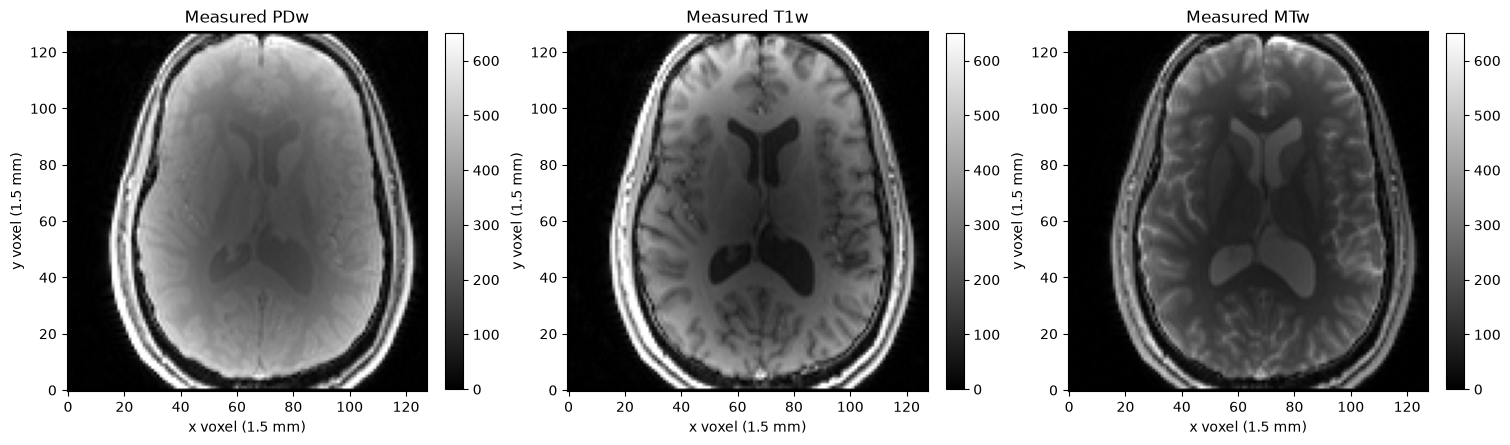

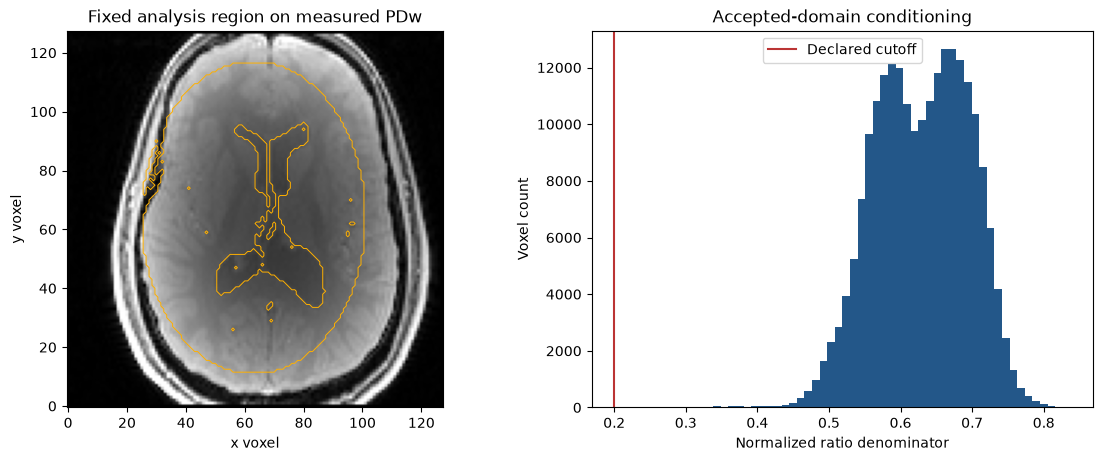

In [2]:
fig=image_grid([data[k] for k in ('PDw','T1w','MTw')],['Measured PDw','Measured T1w','Measured MTw'],[(0,650)]*3,cmap='gray')
plt.show()
fig,ax=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
ax[0].imshow(data['PDw'][:,:,48].T,origin='lower',cmap='gray',vmin=0,vmax=650)
ax[0].contour(mask[:,:,48].T,levels=[.5],colors=['#ffb000'],linewidths=.7)
ax[0].set(title='Fixed analysis region on measured PDw',xlabel='x voxel',ylabel='y voxel')
u=data['PDw']/(6*np.pi/180);v=data['T1w']/(20*np.pi/180)
conditioning=np.abs(u-v)/(u+v+1e-100)
ax[1].hist(conditioning[mask],bins=60,color='#235789');ax[1].axvline(.2,color='#bb3434',label='Declared cutoff')
ax[1].set(xlabel='Normalized ratio denominator',ylabel='Voxel count',title='Accepted-domain conditioning');ax[1].legend();plt.show()


## Physics

For signal $S$, nuisance amplitude $A$, angle $\alpha$ in radians, repetition time $\tau$ in seconds, relaxation rate $R$ in s⁻¹, and fractional saturation $d$, the approximation is

$$
S=\frac{A\alpha\tau R}{\tau R+\alpha^2/2+d}.
$$

The two images without MT have $d=0$. This differs from the exact no-MT Bloch expression $A\sin(\alpha)(1-e^{-\tau R})/(1-\cos(\alpha)e^{-\tau R})$. Comparing them measures approximation error rather than pretending an algebraically perfect three-point fit proves physical accuracy. Nominal excitation angles are used; no measured B1 map is available.

## Method

Write the PD, T1, MT observations as $p,t,m$, their angles as $a,b,c$, and repetition times as $u,v,w$. Eliminate common amplitude to recover

$$
R=\frac{(b/v)t-(a/u)p}{2(p/a-t/b)},\qquad
A=\left(\frac{ub}{a}-\frac{va}{b}\right)\frac{pt}{ubt-vap},
\qquad 100d=100\left[w(cA/m-1)R-c^2/2\right].
$$

This is the published corrected algebraic inverse; no optimization iterations or regularization are required. The local implementation preserves signed estimates and sets the declared outside-domain entries to zero. The nuisance amplitude is recovered again from PDw when predicting measurements for consistency checks. The following cell computes the entire reconstruction afresh.

In [3]:
started=time.perf_counter();fresh=reconstruct(data);elapsed=time.perf_counter()-started
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',**fresh)
results=metrics(fresh,upstream)
print('Fresh local reconstruction seconds:',elapsed)
print(json.dumps(results,indent=2))
amplitude,predicted=predict_from_parameters(data,fresh['reconstruction'][0],fresh['r1'][0],mask)
observed=np.stack([data[k][mask] for k in ('PDw','T1w','MTw')])
print('Signed MTsat range, percent:',np.min(fresh['reconstruction'][0][mask]),np.max(fresh['reconstruction'][0][mask]))
print('Negative MTsat voxels retained:',np.count_nonzero(fresh['reconstruction'][0][mask]<0))


Fresh local reconstruction seconds: 0.06765709997853264
{
  "reconstruction_rmse": 0.0,
  "reconstruction_ncc": 1.0,
  "r1_rmse": 0.0,
  "r1_ncc": 1.0,
  "outside_max": 0.0,
  "observation_relative_rmse": 1.7025282009375949e-16
}
Signed MTsat range, percent: -5.486680425206359 25.5363728260141
Negative MTsat voxels retained: 478


## Results

Spatial maps compare **this notebook's fresh local reconstruction** with **the independently executed original qMRLab result**. Saturation color limits focus on tissue contrast; numerical ranges and negative counts are printed above and all values enter evaluation. Difference maps use explicit percent units. Agreement establishes implementation parity, not biological accuracy.

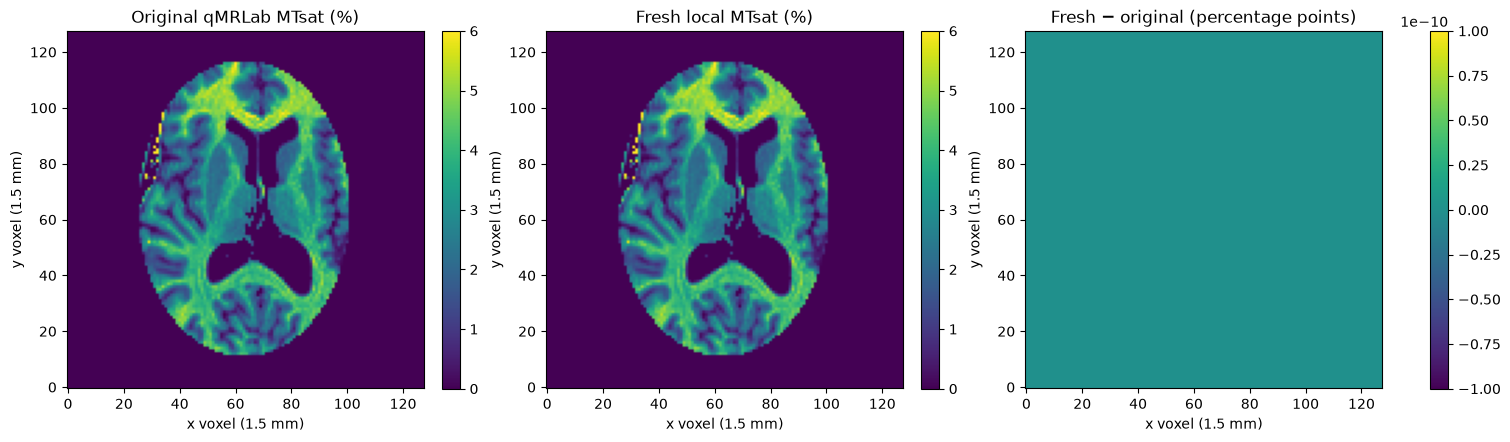

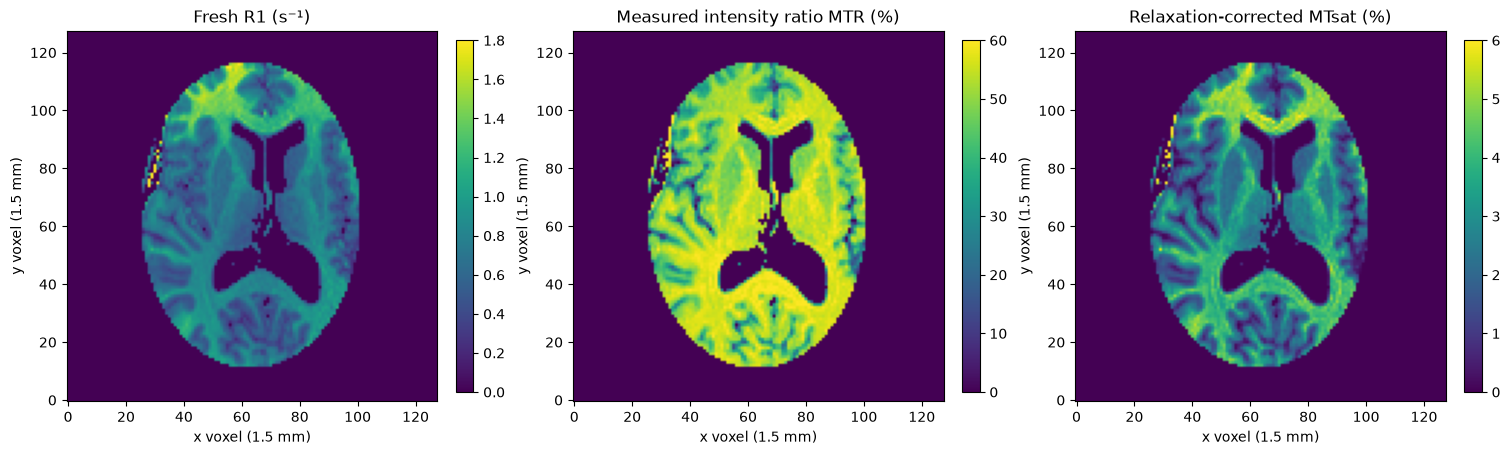

In [4]:
fig=image_grid([upstream['reconstruction'][0],fresh['reconstruction'][0],fresh['reconstruction'][0]-upstream['reconstruction'][0]],['Original qMRLab MTsat (%)','Fresh local MTsat (%)','Fresh − original (percentage points)'],[(0,6),(0,6),(-1e-10,1e-10)])
plt.show()
ratio=mtr(data,mask)
fig=image_grid([fresh['r1'][0],ratio,fresh['reconstruction'][0]],['Fresh R1 (s⁻¹)','Measured intensity ratio MTR (%)','Relaxation-corrected MTsat (%)'],[(0,1.8),(0,60),(0,6)])
plt.show()


MTR and MTsat have different meanings and scales. MTR is a normalized signal loss that retains relaxation dependence; it must not be scored as if it were a saturation reconstruction. The next panels compare actual measured-versus-predicted signals and show the remaining approximation error against the independent Bloch expression.

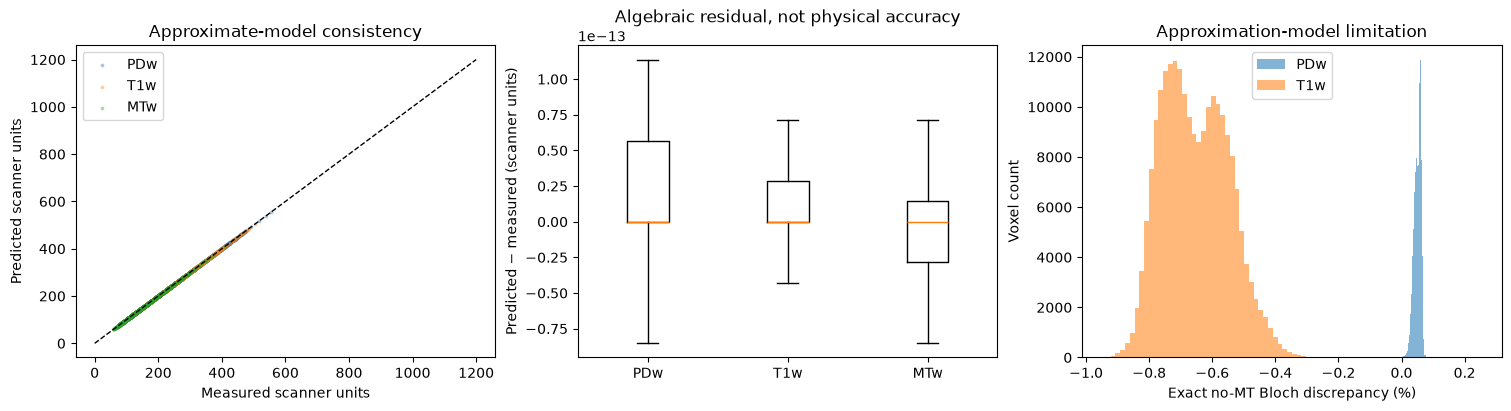

In [5]:
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
idx=np.linspace(0,mask.sum()-1,2500,dtype=int)
for i,name in enumerate(('PDw','T1w','MTw')):
    ax[0].scatter(observed[i,idx],predicted[i,idx],s=3,alpha=.3,label=name)
ax[0].plot([0,1200],[0,1200],'k--',lw=1);ax[0].set(xlabel='Measured scanner units',ylabel='Predicted scanner units',title='Approximate-model consistency');ax[0].legend()
ax[1].boxplot([(predicted[i]-observed[i]) for i in range(3)],tick_labels=['PDw','T1w','MTw'],showfliers=False)
ax[1].set(ylabel='Predicted − measured (scanner units)',title='Algebraic residual, not physical accuracy')
r=fresh['r1'][0][mask]
for i,name in enumerate(('PDw','T1w')):
    bloch=exact_flash_signal(amplitude,r,ANGLES[i],TR[i])
    error=100*(bloch-observed[i])/observed[i]
    ax[2].hist(error,bins=80,alpha=.55,label=name)
ax[2].set(xlabel='Exact no-MT Bloch discrepancy (%)',ylabel='Voxel count',title='Approximation-model limitation');ax[2].legend();plt.show()


The acquisition metadata conflict is scientifically consequential. The labeled ablation below substitutes the header's28ms for T1w18ms while preserving the same method and observations. This is an intentionally incorrect-protocol comparison, not another validated reconstruction. Supplementary1% Gaussian intensity perturbations then probe conditioning; these are explicitly synthetic perturbations of the actual measurement, not new benchmark observations.

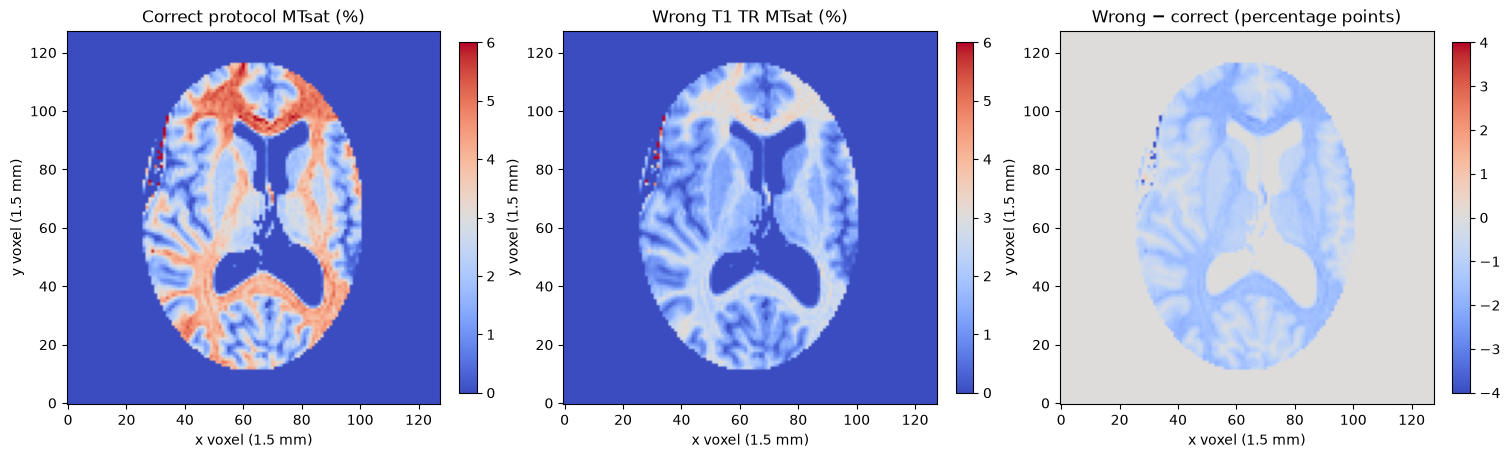

Wrong-TR MTsat RMSE: 1.2047672795243158
Wrong-TR R1 RMSE: 0.38548759144657935


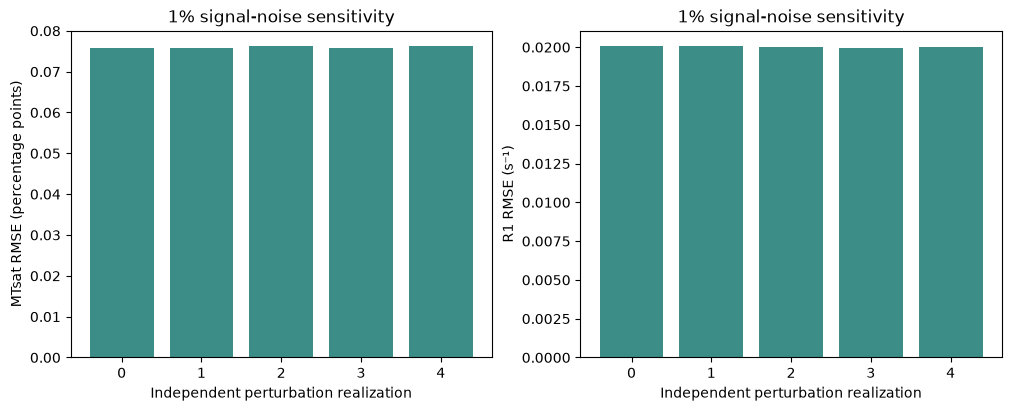

Common-domain voxel counts: [219199, 219186, 219165, 219176, 219182]


In [6]:
wrong=reconstruct(data,repetition_times=np.array([.028,.028,.028]))
fig=image_grid([fresh['reconstruction'][0],wrong['reconstruction'][0],wrong['reconstruction'][0]-fresh['reconstruction'][0]],['Correct protocol MTsat (%)','Wrong T1 TR MTsat (%)','Wrong − correct (percentage points)'],[(0,6),(0,6),(-4,4)],cmap='coolwarm');plt.show()
print('Wrong-TR MTsat RMSE:',comparison_metrics(wrong['reconstruction'][0],fresh['reconstruction'][0],mask)['rmse'])
print('Wrong-TR R1 RMSE:',comparison_metrics(wrong['r1'][0],fresh['r1'][0],mask)['rmse'])
noise_rmse=[];coverage=[]
for seed in range(5):
    rng=np.random.default_rng(seed)
    perturbed={k:a+rng.normal(size=a.shape)*(.01*a) for k,a in data.items()}
    result=reconstruct(perturbed);common=mask&analysis_mask(perturbed);coverage.append(int(common.sum()))
    noise_rmse.append([comparison_metrics(result[k][0],fresh[k][0],common)['rmse'] for k in ('reconstruction','r1')])
fig,ax=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for i,label in enumerate(('MTsat RMSE (percentage points)','R1 RMSE (s⁻¹)')):
    ax[i].bar(np.arange(5),np.array(noise_rmse)[:,i],color='#3c8d87');ax[i].set(xlabel='Independent perturbation realization',ylabel=label,title='1% signal-noise sensitivity')
plt.show();print('Common-domain voxel counts:',coverage)


## Conclusion

The fresh implementation reproduces the independent original method and predicts all three observations under the same approximate model. The maps provide spatial effective MT saturation and relaxation estimates; no physical ground truth was available. MTR retains relaxation confounding, wrong TR metadata changes estimates, and small intensity perturbations reveal sensitivity. A perfect algebraic residual does not remove small-angle approximations, imperfect B1 knowledge, preprocessing uncertainty, or the lack of file-specific scanner identity. The fixed region excludes much unstable background but is not a clinical segmentation. Negative estimates remain visible in reported statistics and are never clipped to manufacture biological plausibility.